# Python机器学习基础教程 ch06：算法链与管道

对应笔记 [ch06.md](../ch06.md)。本 notebook 是**分节跟随代码**：小节结构与笔记一致，完整讲解、原书插图与“坑与陷阱”请看笔记页面。

运行环境：`machinelearn`（Python 3.10 / scikit-learn 1.7 / pandas 2.3 / mglearn，mglearn 已打 boston 本地数据补丁）。原书 0.19 时代 API 的适配处在代码注释中以 **版本适配** 标出，与笔记中的“版本差异” admonition 一一对应。

In [1]:
# ===== 公共设置（notebook 版新增；原书在 Jupyter 全局环境中运行）=====
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import mglearn

# 兜底：nbclient/nbconvert 实跑时 inline 后端的 flush_figures 钩子未注册，
# 图会留在内存不进输出——这里手动补一个“每个 cell 结束时把打开的图显示出来”
import IPython
_ip = IPython.get_ipython()
if _ip is not None:
    def _flush_figs():
        if plt.get_fignums():
            plt.show()
    _ip.events.register("post_execute", _flush_figs)

print("sklearn", sklearn.__version__, "| pandas", pd.__version__,
      "| numpy", np.__version__)

sklearn 1.7.0 | pandas 2.3.3 | numpy 2.2.6


**本章解决**：机器学习应用很少是"一个算法跑到底"——缩放、特征提取、特征选择、模型训练要**链在一起**执行。怎么把这条链封装成一个 scikit-learn 估计器？用 **Pipeline 类（管道）**。本章先看一个反例：预处理放在交叉验证之外做，会"泄漏"验证部分的信息，把随机数据上的回归吹出 R²=0.91（管道纠正后是 -0.25）；然后学管道的创建、fit/predict 链、`步骤名__参数名` 的网格搜索语法，直到"连用哪个模型都交给网格搜索选"。
这一章没有新算法，全是**流程规范与工程接口**，但它决定第 2~5 章所有实验的结论是否可信。学完本章，scikit-learn 提供的通用工具与算法就全部齐了，下一章进入需要专门处理的文本数据。

In [2]:
# ===== 书第 6 章开篇：划分数据 → 缩放 → 训练 SVM =====
from sklearn.svm import SVC
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# 加载并划分数据
cancer = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, random_state=0)

# 计算训练数据的最小值和最大值（fit 只碰训练集——第 3 章立下的铁律）
scaler = MinMaxScaler().fit(X_train)

# 对训练数据进行缩放，然后在缩放后的训练数据上学习 SVM
X_train_scaled = scaler.transform(X_train)
svm = SVC()
svm.fit(X_train_scaled, y_train)

# 对测试数据用同一个缩放器变换，再打分
X_test_scaled = scaler.transform(X_test)
print("Test score: {:.2f}".format(svm.score(X_test_scaled, y_test)))
# → Test score: 0.95

Test score: 0.97


## 6.1 用预处理进行参数选择

现在假设我们想用 GridSearchCV 给 SVC 找更好的参数（正如第 5 章做过的那样）。一种"看起来很自然"的写法是：**先缩放好数据，再在缩放后的数据上跑网格搜索**：

In [3]:
# ===== 书 6.1 节：在"缩放好的数据"上做网格搜索（反例，不要模仿） =====
from sklearn.model_selection import GridSearchCV
# 只是为了便于说明，不要在实践中使用这些代码！
param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100],
              'gamma': [0.001, 0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(SVC(), param_grid=param_grid, cv=5)
grid.fit(X_train_scaled, y_train)          # 注意：喂的是已经缩放过的 X_train_scaled
print("Best cross-validation accuracy: {:.2f}".format(grid.best_score_))
print("Best set score: {:.2f}".format(grid.score(X_test_scaled, y_test)))
print("Best parameters: ", grid.best_params_)
# → Best cross-validation accuracy: 0.98
# → Best set score: 0.97
# → Best parameters:  {'gamma': 1, 'C': 1}

Best cross-validation accuracy: 0.98
Best set score: 0.97
Best parameters:  {'C': 1, 'gamma': 1}


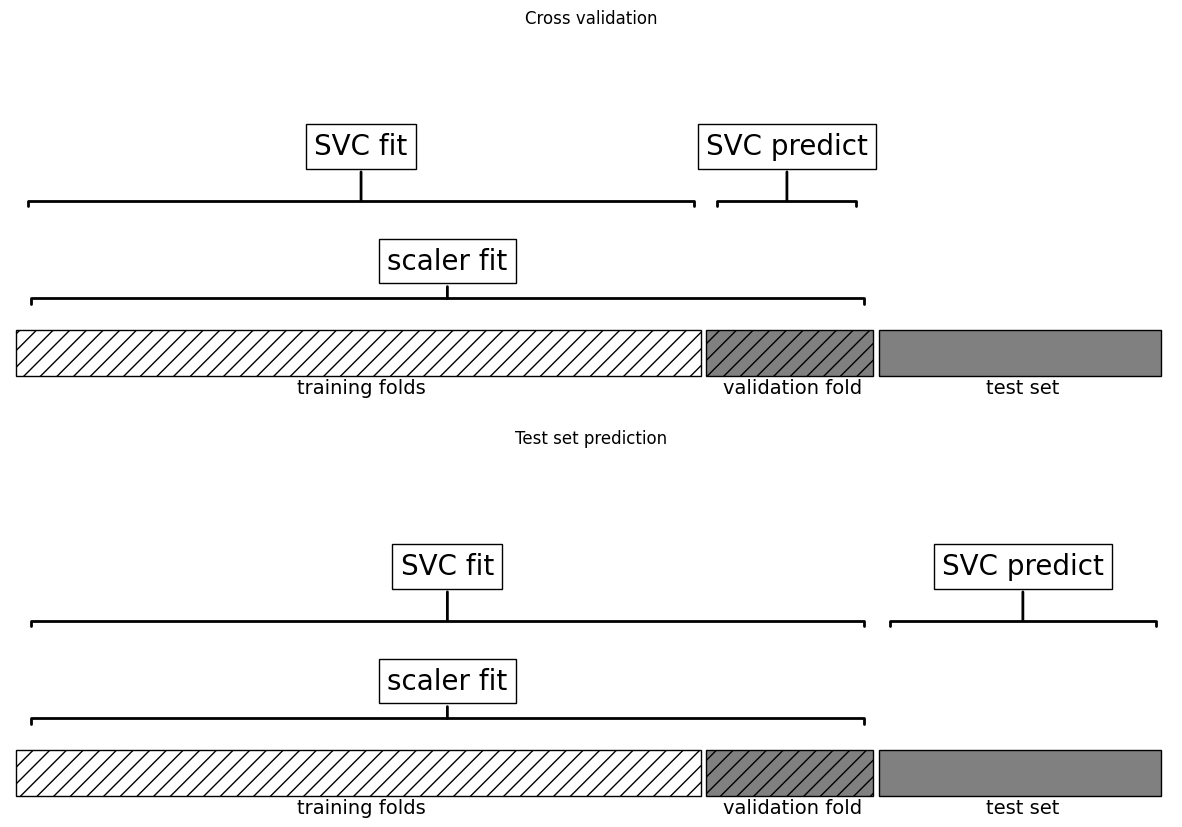

In [4]:
# ===== 书 6.1 节：画出"预处理在交叉验证之外"的数据使用图 =====
mglearn.plots.plot_improper_processing()

## 6.2 构建管道

用 Pipeline 表示"先用 MinMaxScaler 缩放数据、再训练 SVM"这条工作流（暂时不用网格搜索）。第一步，构建一个由**步骤列表**组成的管道对象。每个步骤是一个元组，包含一个名称（你选定的任意字符串）和一个估计器的实例：

In [5]:
# ===== 书 6.2 节：创建两步管道 =====
from sklearn.pipeline import Pipeline
pipe = Pipeline([("scaler", MinMaxScaler()), ("svm", SVC())])

In [6]:
# ===== 书 6.2 节：像普通估计器一样使用管道 =====
pipe.fit(X_train, y_train)      # 一行顶开头的五次手工调用
print("Test score: {:.2f}".format(pipe.score(X_test, y_test)))
# → Test score: 0.95

Test score: 0.97


## 6.3 在网格搜索中使用管道

在网格搜索中使用管道，与使用任何其他估计器一样。唯一的细微变化在参数网格上：**要为每个参数指定它属于管道中的哪一步**。要调的 C 和 gamma 都是 SVC（第二个步骤，名字叫 `"svm"`）的参数。语法：**步骤名称 + `__`（双下划线）+ 参数名称**。所以搜索 SVC 的 C 参数要写 `"svm__C"`，gamma 同理：

In [7]:
# ===== 书 6.3 节：管道内网格搜索 =====
param_grid = {'svm__C': [0.001, 0.01, 0.1, 1, 10, 100],
              'svm__gamma': [0.001, 0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(pipe, param_grid=param_grid, cv=5)
grid.fit(X_train, y_train)        # 注意：这次喂的是未缩放的原始 X_train
print("Best cross-validation accuracy: {:.2f}".format(grid.best_score_))
print("Test set score: {:.2f}".format(grid.score(X_test, y_test)))
print("Best parameters: {}".format(grid.best_params_))
# → Best cross-validation accuracy: 0.98
# → Test set score: 0.97
# → Best parameters: {'svm__C': 1, 'svm__gamma': 1}

Best cross-validation accuracy: 0.98
Test set score: 0.97
Best parameters: {'svm__C': 1, 'svm__gamma': 1}


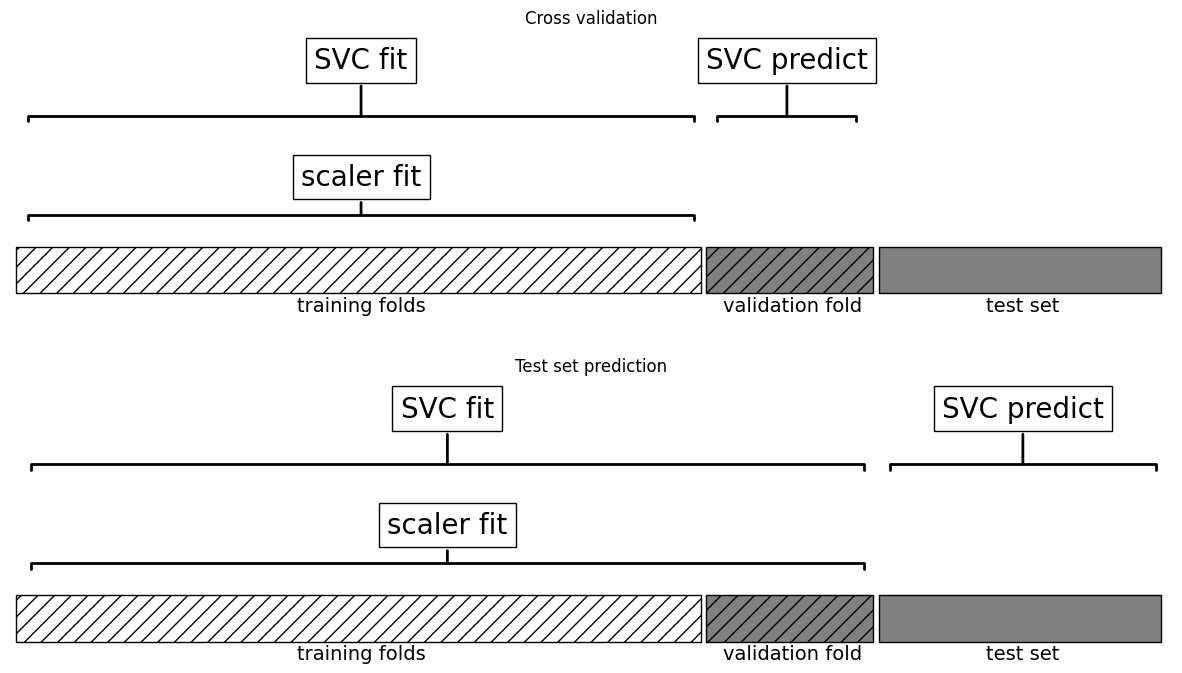

In [8]:
# ===== 书 6.3 节：画出"预处理在交叉验证之内"的数据使用图 =====
mglearn.plots.plot_proper_processing()

### 举例说明信息泄露

考虑一个假想的回归任务：从高斯分布独立采样 100 个样本、10 000 个特征，响应（目标）也从高斯分布采样——**X 与 y 毫无关系，理论上不可能从这个数据集学到任何东西**：

In [9]:
# ===== 书 6.3 节（泄漏实验）：纯随机数据 =====
import numpy as np
rnd = np.random.RandomState(seed=0)
X = rnd.normal(size=(100, 10000))     # 100 个样本、10000 个纯噪声特征
y = rnd.normal(size=(100,))           # 目标也是纯噪声

In [10]:
# ===== 书 6.3 节（泄漏实验）：错误做法——特征选择在交叉验证之外 =====
from sklearn.feature_selection import SelectPercentile, f_regression

select = SelectPercentile(score_func=f_regression, percentile=5).fit(X, y)
X_selected = select.transform(X)      # 在全部 100 个样本上选特征！
print("X_selected.shape: {}".format(X_selected.shape))
# → X_selected.shape: (100, 500)

from sklearn.model_selection import cross_val_score
from sklearn.linear_model import Ridge
print("Cross-validation accuracy (cv only on ridge): {:.2f}".format(
      np.mean(cross_val_score(Ridge(), X_selected, y, cv=5))))
# → Cross-validation accuracy (cv only on ridge): 0.91

X_selected.shape: (100, 500)
Cross-validation accuracy (cv only on ridge): 0.91


In [11]:
# ===== 书 6.3 节（泄漏实验）：正确做法——特征选择进管道 =====
pipe = Pipeline([("select", SelectPercentile(score_func=f_regression,
                                             percentile=5)),
                 ("ridge", Ridge())])
print("Cross-validation accuracy (pipeline): {:.2f}".format(
      np.mean(cross_val_score(pipe, X, y, cv=5))))
# → Cross-validation accuracy (pipeline): -0.25

Cross-validation accuracy (pipeline): -0.25


## 6.4 通用的管道接口

Pipeline 不只能用于"预处理 + 分类"，实际上可以把**任意数量的估计器**连接在一起。例如构建一个包含**特征提取、特征选择、缩放、分类**的管道，总共 4 个步骤。最后一步也可以换成回归或聚类。

In [12]:
# ===== 书 6.4 节：Pipeline.fit 的等价实现（示意，忽略细节） =====
def fit(self, X, y):
    X_transformed = X
    for name, estimator in self.steps[:-1]:
        # 遍历除最后一步之外的所有步骤
        # 对数据进行拟合和变换
        X_transformed = estimator.fit_transform(X_transformed, y)
    # 对最后一步进行拟合
    self.steps[-1][1].fit(X_transformed, y)
    return self

In [13]:
# ===== 书 6.4 节：Pipeline.predict 的等价实现（示意） =====
def predict(self, X):
    X_transformed = X
    for step in self.steps[:-1]:
        # 遍历除最后一步之外的所有步骤
        # 对数据进行变换
        X_transformed = step[1].transform(X_transformed)
    # 利用最后一步进行预测
    return self.steps[-1][1].predict(X_transformed)

### 6.4.1 用 make_pipeline 方便地创建管道

上面的语法有时有点麻烦——通常并不需要为每个步骤提供自定义名称。便捷函数 **make_pipeline** 可以创建管道并**根据每个步骤所属的类自动命名**：

In [14]:
# ===== 书 6.4.1 节：两种创建管道的写法 =====
from sklearn.pipeline import make_pipeline
# 标准语法
pipe_long = Pipeline([("scaler", MinMaxScaler()), ("svm", SVC(C=100))])
# 缩写语法
pipe_short = make_pipeline(MinMaxScaler(), SVC(C=100))

In [15]:
# ===== 书 6.4.1 节：查看自动生成的步骤名 =====
print("Pipeline steps:\n{}".format(pipe_short.steps))
# → [('minmaxscaler', MinMaxScaler(copy=True, feature_range=(0, 1))),
#    ('svc', SVC(C=100, ...))]        ← 书印为完整参数列表，此处省略

Pipeline steps:
[('minmaxscaler', MinMaxScaler()), ('svc', SVC(C=100))]


In [16]:
# ===== 书 6.4.1 节：同类步骤自动加序号 =====
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pipe = make_pipeline(StandardScaler(), PCA(n_components=2), StandardScaler())
print("Pipeline steps:\n{}".format(pipe.steps))
# → [('standardscaler-1', StandardScaler(...)),
#    ('pca', PCA(n_components=2, ...)),
#    ('standardscaler-2', StandardScaler(...))]

Pipeline steps:
[('standardscaler-1', StandardScaler()), ('pca', PCA(n_components=2)), ('standardscaler-2', StandardScaler())]


### 6.4.2 访问步骤属性

通常你希望检查管道中某一步的属性——比如线性模型的系数，或 PCA 提取的成分。访问管道步骤最简单的方法是 **`named_steps` 属性**：它是一个字典，把步骤名称映射为估计器：

In [17]:
# ===== 书 6.4.2 节：named_steps 访问步骤属性 =====
# 用上面定义的管道对 cancer 数据集进行拟合
pipe.fit(cancer.data)
# 从"pca"步骤中提取前两个主成分
components = pipe.named_steps["pca"].components_
print("components.shape: {}".format(components.shape))
# → components.shape: (2, 30)

components.shape: (2, 30)


### 6.4.3 访问网格搜索管道中的属性

使用管道的主要原因之一就是网格搜索，而常见任务是在网格搜索**内部**访问管道某一步的属性。场景：对 cancer 数据集上的 LogisticRegression 做网格搜索，在数据传入分类器之前先用 Pipeline 和 StandardScaler 缩放。先用 make_pipeline 创建管道：

In [18]:
# ===== 书 6.4.3 节：网格搜索管道 =====
from sklearn.linear_model import LogisticRegression

pipe = make_pipeline(StandardScaler(), LogisticRegression())

In [19]:
# ===== 书 6.4.3 节：参数网格与搜索 =====
param_grid = {'logisticregression__C': [0.01, 0.1, 1, 10, 100]}

X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, random_state=4)
grid = GridSearchCV(pipe, param_grid, cv=5)
grid.fit(X_train, y_train)

,estimator,Pipeline(step...egression())])
,param_grid,"{'logisticregression__C': [0.01, 0.1, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


In [20]:
# ===== 书 6.4.3 节：从 GridSearchCV 里"挖出"最佳模型 =====
print("Best estimator:\n{}".format(grid.best_estimator_))
# → Pipeline(steps=[('standardscaler', StandardScaler(...)),
#                   ('logisticregression', LogisticRegression(C=0.1, ...))])

Best estimator:
Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(C=1))])


In [21]:
# ===== 书 6.4.3 节：取最佳模型、读系数 =====
print("Logistic regression step:\n{}".format(
      grid.best_estimator_.named_steps["logisticregression"]))
# → LogisticRegression(C=0.1, ...)

print("Logistic regression coefficients:\n{}".format(
      grid.best_estimator_.named_steps["logisticregression"].coef_))
# → Logistic regression coefficients:
#   [[-0.389 -0.375 -0.376 -0.396 -0.115  0.017 -0.355 -0.39  -0.058  0.209
#     -0.495 -0.004 -0.371 -0.383 -0.045  0.198  0.004 -0.049  0.21   0.224
#     -0.547 -0.525 -0.499 -0.515 -0.393 -0.123 -0.388 -0.417 -0.325 -0.139]]

Logistic regression step:
LogisticRegression(C=1)
Logistic regression coefficients:
[[-0.4475566  -0.34609376 -0.41703843 -0.52889408 -0.15784407  0.60271339
  -0.71771325 -0.78367478  0.04847448  0.27478533 -1.29504052  0.05314385
  -0.69103766 -0.91925087 -0.14791795  0.46138699 -0.1264859  -0.10289486
   0.42812714  0.71492797 -1.08532414 -1.09273614 -0.85133685 -1.04104568
  -0.72839683  0.07656216 -0.83641023 -0.64928603 -0.6491432  -0.42968125]]


## 6.5 网格搜索预处理步骤与模型参数

用管道可以把机器学习工作流中的**所有处理步骤**封装成一个 scikit-learn 估计器。这么做的另一个好处：**可以用监督任务（回归/分类）的输出来调节预处理参数**——预处理不再凭经验拍脑袋，而是被交叉验证选中。

In [22]:
# ===== 书 6.5 节：缩放 + 多项式特征 + 岭回归，三步管道 =====
from mglearn.datasets import load_boston  # 版本适配：sklearn≥1.2 移除 load_boston，改用 mglearn 内置等价加载（本地缓存）
# 版本适配：mglearn 内置等价加载（boston.data/target 用法不变，本地缓存离线可跑）
from mglearn.datasets import load_boston
boston = load_boston()
X_train, X_test, y_train, y_test = train_test_split(boston.data, boston.target,
                                                    random_state=0)

from sklearn.preprocessing import PolynomialFeatures
pipe = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(),     # 默认 degree=2
    Ridge())

In [23]:
# ===== 书 6.5 节：同时搜索预处理参数与模型参数 =====
param_grid = {'polynomialfeatures__degree': [1, 2, 3],
              'ridge__alpha': [0.001, 0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(pipe, param_grid=param_grid, cv=5, n_jobs=-1)
grid.fit(X_train, y_train)

,estimator,"Pipeline(step...e', Ridge())])"
,param_grid,"{'polynomialfeatures__degree': [1, 2, ...], 'ridge__alpha': [0.001, 0.01, ...]}"
,scoring,None
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


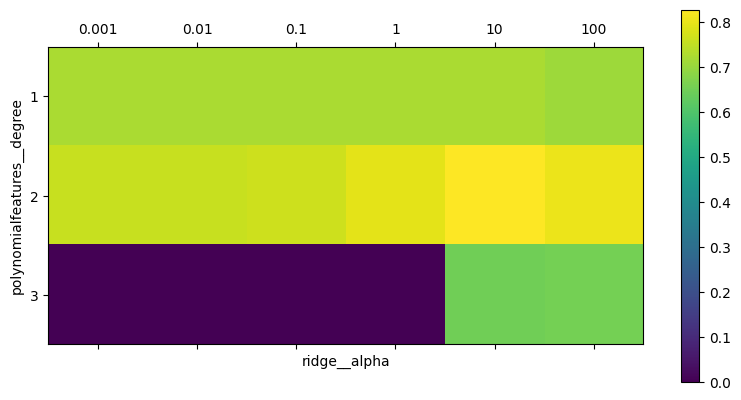

In [24]:
# ===== 书 6.5 节：交叉验证分数热图 =====
plt.matshow(grid.cv_results_['mean_test_score'].reshape(3, -1),
            vmin=0, cmap="viridis")
plt.xlabel("ridge__alpha")
plt.ylabel("polynomialfeatures__degree")
plt.xticks(range(len(param_grid['ridge__alpha'])), param_grid['ridge__alpha'])
plt.yticks(range(len(param_grid['polynomialfeatures__degree'])),
           param_grid['polynomialfeatures__degree'])
plt.colorbar()

In [25]:
# ===== 书 6.5 节：最佳参数与测试分数 =====
print("Best parameters: {}".format(grid.best_params_))
# → Best parameters: {'polynomialfeatures__degree': 2, 'ridge__alpha': 10}

print("Test-set score: {:.2f}".format(grid.score(X_test, y_test)))
# → Test-set score: 0.77

# 对比：运行一个没有多项式特征的网格搜索
param_grid = {'ridge__alpha': [0.001, 0.01, 0.1, 1, 10, 100]}
pipe = make_pipeline(StandardScaler(), Ridge())
grid = GridSearchCV(pipe, param_grid, cv=5)
grid.fit(X_train, y_train)
print("Score without poly features: {:.2f}".format(grid.score(X_test, y_test)))
# → Score without poly features: 0.63

Best parameters: {'polynomialfeatures__degree': 2, 'ridge__alpha': 10}
Test-set score: 0.77
Score without poly features: 0.63


## 6.6 网格搜索选择使用哪个模型

还可以更进一步：把 GridSearchCV 和 Pipeline 结合起来，**搜索管道中正在执行的实际步骤**——比如用 StandardScaler 还是用 MinMaxScaler，甚至分类器用 SVC 还是随机森林。这会导致更大的搜索空间，应当仔细考虑；**尝试所有可能的解决方案，通常并不是一种可行的机器学习策略**。但作为一个例子，我们比较 RandomForestClassifier 和 SVC：

In [26]:
# ===== 书 6.6 节：显式命名的两步管道 =====
pipe = Pipeline([('preprocessing', StandardScaler()), ('classifier', SVC())])

In [27]:
# ===== 书 6.6 节：参数网格列表——连"用哪个模型"都交给搜索 =====
from sklearn.ensemble import RandomForestClassifier

param_grid = [
    {'classifier': [SVC()], 'preprocessing': [StandardScaler(), None],
     'classifier__gamma': [0.001, 0.01, 0.1, 1, 10, 100],
     'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100]},
    {'classifier': [RandomForestClassifier(n_estimators=100)],
     'preprocessing': [None], 'classifier__max_features': [1, 2, 3]}]

In [28]:
# ===== 书 6.6 节：在 cancer 上运行"选模型"网格搜索 =====
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, random_state=0)

grid = GridSearchCV(pipe, param_grid, cv=5)
grid.fit(X_train, y_train)
print("Best params:\n{}\n".format(grid.best_params_))
print("Best cross-validation score: {:.2f}".format(grid.best_score_))
print("Test-set score: {:.2f}".format(grid.score(X_test, y_test)))
# → Best params:
# → {'classifier': SVC(C=10, gamma=0.01, ...),
# →  'preprocessing': StandardScaler(...),
# →  'classifier__C': 10, 'classifier__gamma': 0.01}
# → Best cross-validation score: 0.99
# → Test-set score: 0.98

Best params:
{'classifier': SVC(), 'classifier__C': 10, 'classifier__gamma': 0.01, 'preprocessing': StandardScaler()}

Best cross-validation score: 0.99
Test-set score: 0.98


## 6.7 小结与展望

本章介绍了 **Pipeline 类**——一种通用工具，可以把机器学习工作流中的多个处理步骤链接在一起。现实世界的机器学习应用很少只单独使用一个模型，而是一系列处理步骤。使用管道可以把多个步骤封装成**单个 Python 对象**，它具有我们熟悉的 scikit-learn 接口：`fit`、`predict` 和 `transform`。